# ShopSmart Retail Group — Data Preprocessing & Feature Engineering for Machine Learning
**AnalystLab Africa · Machine Learning Internship · Week 2**

**Author:** Umar Muhammad  |  **Dataset:** ShopSmart Retail Group (same dataset as Week 1)

---
## 0. Business Understanding
ShopSmart Retail Group runs 25 stores across Nigeria and sells online and in-store. In Week 1 we built baseline models for two problems:

| Problem | Type | Target |
|---|---|---|
| Predict how much an order is worth | Regression | `Order_Value` |
| Predict whether an order will be returned | Classification | `Is_Returned` |

Week 1 exposed two issues: the regression looked perfect (R² = 1.0) because the target was reconstructed from its own inputs, and the classifier reached 95% accuracy while catching **zero** returns, because only about 5% of orders are returned.

**Objective of this notebook:** turn the nine raw ShopSmart tables into one clean, documented, leakage-aware, machine-learning-ready table, and answer the seven business questions in the assignment. Every decision is explained next to the code that performs it.

**Pipeline overview:** Inspect → Audit quality → Clean → Engineer features → Split → Encode → Scale → Detect outliers → Select features → Save.

## 1. Setup

In [1]:
import json, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import LabelEncoder, OrdinalEncoder, StandardScaler, MinMaxScaler, RobustScaler
from sklearn.feature_selection import VarianceThreshold, mutual_info_classif
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.metrics import r2_score

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams.update({"figure.dpi": 100, "axes.titlesize": 13, "axes.titleweight": "bold"})

RANDOM_STATE = 42
RAW, OUT, IMG, REP, MOD = (Path("../data/raw"), Path("../data/processed"), Path("../images"),
                           Path("../reports"), Path("../models"))
results = {}   # facts collected here are reused by the written reports

def save_fig(name):
    plt.tight_layout()
    plt.savefig(IMG / name, dpi=150, bbox_inches="tight")
    plt.show()

## 2. Part 1 — Data Inspection
We load all nine tables. Four of them (orders, order items, customers, products) plus stores and returns feed the order-level modelling table. Employees, inventory and suppliers are inspected for quality but do not describe an individual order, so they are not joined.

In [2]:
files = {
    "customers": "ALA_ShopSmart_Customers.csv", "orders": "ShopSmart_Orders.csv",
    "order_items": "ShopSmart_Order_Items.csv", "products": "ShopSmart_Products.csv",
    "stores": "ShopSmart_Stores.csv", "returns": "ShopSmart_Returns.csv",
    "employees": "ShopSmart_Employees.csv", "inventory": "ShopSmart_Inventory.csv",
    "suppliers": "ShopSmart_Suppliers.csv",
}
tables = {name: pd.read_csv(RAW / f) for name, f in files.items()}

overview = pd.DataFrame([{
    "table": n, "rows": d.shape[0], "columns": d.shape[1],
    "missing_cells": int(d.isna().sum().sum()), "duplicate_rows": int(d.duplicated().sum())}
    for n, d in tables.items()])
overview

,table,rows,columns,missing_cells,duplicate_rows
0,customers,5000,11,0,0
1,orders,50000,12,0,0
2,order_items,50000,7,0,0
3,products,500,7,0,0
4,stores,25,6,0,0
5,returns,2500,5,0,0
6,employees,125,6,0,0
7,inventory,500,6,0,0
8,suppliers,489,6,0,0


**First 10 rows of the main table (`orders`):**

In [3]:
tables['orders'].head(10)

,Order_ID,Customer_ID,Product_ID,Store_ID,Order_Date,Quantity,Unit_Price,Discount,Shipping_Cost,Payment_Method,Sales_Channel,Order_Status
0,ORD000001,CUST04572,PROD0244,STR005,7/19/2025,1,77989,10,3833,Card,Online,Completed
1,ORD000002,CUST04064,PROD0432,STR010,3/15/2025,3,11240,5,2872,Card,In-Store,Cancelled
2,ORD000003,CUST03435,PROD0052,STR004,10/1/2025,2,23595,20,922,Card,Online,Pending
3,ORD000004,CUST03536,PROD0051,STR023,7/15/2025,4,69922,5,911,Transfer,Online,Completed
4,ORD000005,CUST03676,PROD0356,STR021,3/28/2025,5,53344,0,1740,Card,Online,Cancelled
5,ORD000006,CUST03203,PROD0458,STR014,3/11/2025,3,31991,0,3452,Card,In-Store,Cancelled
6,ORD000007,CUST00082,PROD0174,STR015,9/1/2025,5,5086,20,3064,Card,Online,Completed
7,ORD000008,CUST01119,PROD0171,STR019,1/7/2025,4,32902,0,4279,Card,In-Store,Completed
8,ORD000009,CUST00284,PROD0336,STR015,3/29/2025,2,99649,5,1266,Card,Online,Cancelled
9,ORD000010,CUST00338,PROD0381,STR017,8/30/2025,4,75235,0,3693,Transfer,Online,Completed


**Dimensions and data types** of the order, customer and product tables:

In [4]:
for n in ["orders", "order_items", "customers", "products", "returns"]:
    print(f"--- {n}: {tables[n].shape[0]:,} rows x {tables[n].shape[1]} columns")
    print(tables[n].dtypes.to_string(), "\n")

--- orders: 50,000 rows x 12 columns
Order_ID            str
Customer_ID         str
Product_ID          str
Store_ID            str
Order_Date          str
Quantity          int64
Unit_Price        int64
Discount          int64
Shipping_Cost     int64
Payment_Method      str
Sales_Channel       str
Order_Status        str 

--- order_items: 50,000 rows x 7 columns
Order_Item_ID      str
Order_ID           str
Product_ID         str
Quantity         int64
Unit_Price       int64
Discount         int64
Line_Total       int64 

--- customers: 5,000 rows x 11 columns
Customer_ID            str
First_Name             str
Last_Name              str
Gender                 str
Age                  int64
Email                  str
Phone                  str
City                   str
State                  str
Registration_Date      str
Customer_Segment       str 

--- products: 500 rows x 7 columns
Product_ID           str
Product_Name         str
Category             str
Sub_Category         

**Missing values and duplicates** (per table, from the overview above), plus descriptive statistics:

In [5]:
print("Total missing cells across all 9 tables:", int(overview.missing_cells.sum()))
print("Total fully-duplicated rows across all 9 tables:", int(overview.duplicate_rows.sum()))
tables["orders"].describe().T.round(2)

Total missing cells across all 9 tables: 0
Total fully-duplicated rows across all 9 tables: 0


,count,mean,std,min,25%,50%,75%,max
Quantity,50000.0,3.00,1.41,1.0,2.00,3.0,4.0,5.0
Unit_Price,50000.0,50428.61,28582.92,1003.0,25648.75,50631.0,75123.0,99998.0
Discount,50000.0,9.97,7.09,0.0,5.00,10.0,15.0,20.0
Shipping_Cost,50000.0,2747.71,1296.19,500.0,1628.00,2751.0,3866.0,5000.0


In [6]:
tables['customers'].describe(include='all').T.round(2)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Customer_ID,5000,5000,CUST00001,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
First_Name,5000,595,Michael,120,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Last_Name,5000,916,Smith,121,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Gender,5000,2,Male,2557,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,5000.0,NaN,NaN,NaN,44.1508,15.382555,18.0,30.0,44.0,58.0,70.0
Email,5000,4951,jennifer26@example.com,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Phone,5000,4996,-7645,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
City,5000,10,Port Harcourt,531,NaN,NaN,NaN,NaN,NaN,NaN,NaN
State,5000,10,Rivers,531,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Registration_Date,5000,995,7/23/2023,14,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [7]:
tables['order_items'].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
Quantity,50000.0,3.00,1.41,1.0,2.00,3.0,4.00,5.0
Unit_Price,50000.0,50428.61,28582.92,1003.0,25648.75,50631.0,75123.00,99998.0
Discount,50000.0,9.97,7.09,0.0,5.00,10.0,15.00,20.0
Line_Total,50000.0,151505.00,119086.34,993.0,55957.25,118844.0,225787.75,499960.0


**First reading of the inspection.** There are no missing cells and no exact duplicate rows in any table, and every foreign key resolves. That is unusual for real data, so a clean-looking summary is not enough. The next step audits the *logic* of the data (does it make business sense?), which is where the real problems are.

### 2.1 Data-quality audit (logic checks)

In [8]:
o, oi, c, p = tables["orders"], tables["order_items"], tables["customers"], tables["products"]
r, s, sup = tables["returns"], tables["stores"], tables["suppliers"]

o_dates = pd.to_datetime(o.Order_Date, format="%m/%d/%Y")
audit = []
def add(issue, table, n, base, impact):
    audit.append({"issue": issue, "table": table, "records_affected": int(n),
                  "pct_of_records": round(100 * n / base, 1), "impact": impact})

# 1. Line_Total arithmetic: is Discount a percentage or a flat amount?
flat = (oi.Quantity * oi.Unit_Price - oi.Discount)
pct  = (oi.Quantity * oi.Unit_Price * (1 - oi.Discount / 100))
add("Line_Total subtracts Discount as a flat number (not as a %)", "order_items",
    (flat == oi.Line_Total).sum(), len(oi), "Target is a deterministic formula of its inputs (leakage); discount effect is negligible")
results["pct_formula_match"] = float((pct.round() == oi.Line_Total).mean())

# 2. Unit price on the order vs the product catalogue
mp = o.merge(p[["Product_ID", "Selling_Price"]], on="Product_ID")
add("Order Unit_Price differs from catalogue Selling_Price (>1 unit)", "orders vs products",
    ((mp.Unit_Price - mp.Selling_Price).abs() > 1).sum(), len(mp), "Two conflicting price sources; order price used")

# 3-6. Returns logic
rr = r.merge(o[["Order_ID", "Order_Date", "Order_Status"]], on="Order_ID")
rr["gap"] = (pd.to_datetime(rr.Return_Date, format="%m/%d/%Y") - pd.to_datetime(rr.Order_Date, format="%m/%d/%Y")).dt.days
add("Returns recorded on Cancelled/Pending orders", "returns", (rr.Order_Status != "Completed").sum(), len(rr), "Impossible business flow; Order_Status kept but treated with caution")
add("Return_Date earlier than Order_Date", "returns", (rr.gap < 0).sum(), len(rr), "Return timing is unreliable; not used as a feature")
add("Orders with more than one return record", "returns", len(r) - r.Order_ID.nunique(), len(r), "Collapsed to one order-level flag")
rl = r.merge(oi[["Order_ID", "Line_Total"]], on="Order_ID")
add("Refund_Amount larger than the order's Line_Total", "returns", (rl.Refund_Amount > rl.Line_Total).sum(), len(rl), "Refund amount not used (post-event, inconsistent)")

# 7. Customers
reg = pd.to_datetime(c.set_index("Customer_ID").Registration_Date, format="%m/%d/%Y")
before = (o_dates < o.Customer_ID.map(reg)).sum()
add("Order placed before the customer's registration date", "orders vs customers", before, len(o), "Tenure would be negative; clipped to 0 and flagged")
add("Duplicate customer e-mail addresses", "customers", c.Email.duplicated().sum(), len(c), "E-mail is personal data; dropped")
add("Duplicate customer phone numbers", "customers", c.Phone.duplicated().sum(), len(c), "Phone is personal data; dropped (formats are also inconsistent)")

# 8. Stores
reg_per_state = s.groupby("State").Region.nunique()
add("States that appear under more than one Region", "stores", (reg_per_state > 1).sum(), s.State.nunique(), "Store_Region is unreliable; kept as a weak feature")
add("Store names that are duplicated", "stores", s.Store_Name.duplicated().sum(), len(s), "Store_ID used as the key, name dropped")

# 9. Products / suppliers
add("Sub_Category holds a single constant value ('General')", "products", len(p), len(p), "Zero information; dropped")
add("Suppliers with malformed phone numbers (<7 digits)", "suppliers",
    (sup.Phone.str.replace(r"\D", "", regex=True).str.len() < 7).sum(), len(sup), "Table not used in the model")

audit = pd.DataFrame(audit)
results["audit"] = audit.to_dict("records")
audit

,issue,table,records_affected,pct_of_records,impact
0,Line_Total subtracts Discount as a flat number...,order_items,50000,100.0,Target is a deterministic formula of its input...
1,Order Unit_Price differs from catalogue Sellin...,orders vs products,50000,100.0,Two conflicting price sources; order price used
2,Returns recorded on Cancelled/Pending orders,returns,1685,67.4,Impossible business flow; Order_Status kept bu...
3,Return_Date earlier than Order_Date,returns,1252,50.1,Return timing is unreliable; not used as a fea...
4,Orders with more than one return record,returns,58,2.3,Collapsed to one order-level flag
5,Refund_Amount larger than the order's Line_Total,returns,270,10.8,"Refund amount not used (post-event, inconsistent)"
6,Order placed before the customer's registratio...,orders vs customers,5159,10.3,Tenure would be negative; clipped to 0 and fla...
7,Duplicate customer e-mail addresses,customers,49,1.0,E-mail is personal data; dropped
8,Duplicate customer phone numbers,customers,4,0.1,Phone is personal data; dropped (formats are a...
9,States that appear under more than one Region,stores,6,60.0,Store_Region is unreliable; kept as a weak fea...


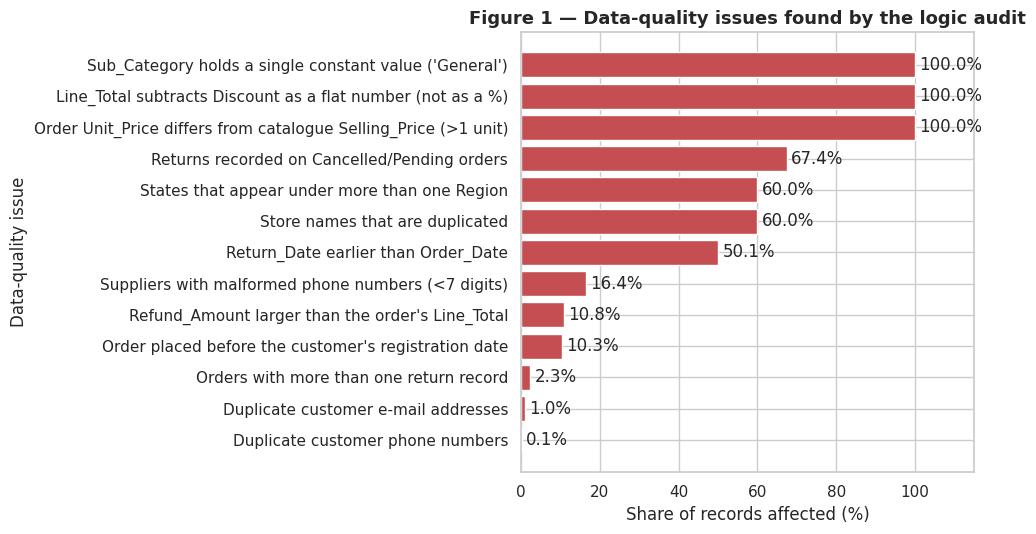

In [9]:
fig, ax = plt.subplots(figsize=(10, 5.5))
plot_df = audit.sort_values("pct_of_records")
bars = ax.barh(plot_df.issue.str.slice(0, 70), plot_df.pct_of_records, color=sns.color_palette("deep")[3])
ax.bar_label(bars, fmt="%.1f%%", padding=3)
ax.set_xlabel("Share of records affected (%)")
ax.set_ylabel("Data-quality issue")
ax.set_title("Figure 1 — Data-quality issues found by the logic audit")
ax.set_xlim(0, 115)
save_fig("01_data_quality_issues.png")

**What the audit tells us (Business Question 1).**
* The tables are *structurally* clean but *logically* flawed. The most important flaw is #1: `Line_Total = Quantity × Unit_Price − Discount`, where `Discount` is a 0–20 whole number that looks like a percentage. As a flat deduction it removes only a few naira from totals of about 150,000, so `Order_Value` is almost exactly `Quantity × Unit_Price`. This is why the Week 1 regression scored R² = 1.0.
* Returns data is inconsistent (returns on cancelled orders, returns dated before the purchase), so the only safe use of it is the simple fact *"this order has a return record"*.
* Roughly 10% of orders pre-date the customer's registration. We keep the rows but flag them.

## 3. Part 2 — Data Cleaning
Each decision below is explained in the comment/markdown that accompanies it.

In [10]:
# --- 3.1 Standardise text (strip stray spaces, consistent case) -------------------------
for name in ["customers", "orders", "products", "stores", "returns"]:
    d = tables[name]
    for col in d.columns:
        if pd.api.types.is_string_dtype(d[col]) or d[col].dtype == object:
            d[col] = d[col].str.strip()
for col in ["Payment_Method", "Sales_Channel", "Order_Status"]:
    tables["orders"][col] = tables["orders"][col].str.title()
print("Text standardised. Category levels after cleaning:")
for col in ["Payment_Method", "Sales_Channel", "Order_Status"]:
    print(f"  {col}: {sorted(tables['orders'][col].unique())}")

Text standardised. Category levels after cleaning:
  Payment_Method: ['Card', 'Cash', 'Transfer']
  Sales_Channel: ['In-Store', 'Online']
  Order_Status: ['Cancelled', 'Completed', 'Pending']


**Decision — text values.** The levels were already consistent (no `online`/`Online` variants), so stripping and title-casing changes nothing today but protects the pipeline if the data is refreshed.

In [11]:
# --- 3.2 Duplicates ------------------------------------------------------------------
before = {n: len(d) for n, d in tables.items()}
for n in tables:
    tables[n] = tables[n].drop_duplicates().reset_index(drop=True)
removed = {n: before[n] - len(tables[n]) for n in tables}
print("Exact duplicate rows removed per table:", removed)
assert tables["orders"].Order_ID.is_unique and tables["order_items"].Order_ID.is_unique
print("Order_ID is unique in orders and order_items -> a safe 1:1 join.")

Exact duplicate rows removed per table: {'customers': 0, 'orders': 0, 'order_items': 0, 'products': 0, 'stores': 0, 'returns': 0, 'employees': 0, 'inventory': 0, 'suppliers': 0}
Order_ID is unique in orders and order_items -> a safe 1:1 join.


**Decision — duplicates.** No exact duplicates exist, so nothing was dropped. The real duplication problem is that 58 orders have two return records. That is handled by collapsing returns to one flag per order in the next step.

In [12]:
# --- 3.3 Missing values --------------------------------------------------------------
print("Missing cells after cleaning:", sum(int(d.isna().sum().sum()) for d in tables.values()))

Missing cells after cleaning: 0


**Decision — missing values.** There are none, so no imputation was needed. (If there had been, the plan was: median for skewed numeric columns, mode for categorical columns, and a missing-indicator flag where missingness could carry meaning.) Importantly, *do not invent missing values to look busy*; the honest finding is that the raw data is complete.

In [13]:
# --- 3.4 Data-type corrections -------------------------------------------------------
o, oi, c, p, s, r = (tables[k].copy() for k in ["orders", "order_items", "customers", "products", "stores", "returns"])

# Dates arrive as text such as '7/19/2025' (month/day/year) -> real datetimes
o["Order_Date"] = pd.to_datetime(o.Order_Date, format="%m/%d/%Y")
c["Registration_Date"] = pd.to_datetime(c.Registration_Date, format="%m/%d/%Y")
s["Opening_Date"] = pd.to_datetime(s.Opening_Date, format="%m/%d/%Y")
r["Return_Date"] = pd.to_datetime(r.Return_Date, format="%m/%d/%Y")

# Low-cardinality text -> category (saves memory, signals intent)
for col in ["Payment_Method", "Sales_Channel", "Order_Status"]:
    o[col] = o[col].astype("category")
for col in ["Gender", "Customer_Segment"]:
    c[col] = c[col].astype("category")
p["Category"] = p["Category"].astype("category")

# Validation: ranges that must hold
assert o.Quantity.between(1, 5).all() and o.Discount.between(0, 20).all()
assert (o.Unit_Price > 0).all() and (o.Shipping_Cost > 0).all() and c.Age.between(18, 100).all()
print("Dates parsed:", o.Order_Date.min().date(), "->", o.Order_Date.max().date())
print("Validation passed: Quantity 1-5, Discount 0-20, prices > 0, Age 18-100.")

Dates parsed: 2025-01-01 -> 2025-12-31
Validation passed: Quantity 1-5, Discount 0-20, prices > 0, Age 18-100.


**Decision — types.** Dates were stored as strings, which would have broken any time-based feature, so they are parsed with an explicit `%m/%d/%Y` format (an automatic guess could silently swap day and month). Range assertions double as *data-type validation*: they fail loudly if a future file contains impossible values.

In [14]:
# --- 3.5 Build one order-level table (1 row = 1 order) -------------------------------
# Collapse returns to a single flag per order (target for classification).
ret_flag = r.groupby("Order_ID").size().rename("Return_Count").reset_index()

df = (o.merge(oi[["Order_ID", "Line_Total"]], on="Order_ID", how="left", validate="1:1")
        .merge(c.rename(columns={"State": "Customer_State", "City": "Customer_City"}),
               on="Customer_ID", how="left", validate="m:1")
        .merge(p[["Product_ID", "Category", "Cost_Price", "Selling_Price"]],
               on="Product_ID", how="left", validate="m:1")
        .merge(s.rename(columns={"State": "Store_State", "City": "Store_City", "Region": "Store_Region"})
                 [["Store_ID", "Store_State", "Store_Region", "Opening_Date"]],
               on="Store_ID", how="left", validate="m:1")
        .merge(ret_flag, on="Order_ID", how="left"))

df["Is_Returned"] = df.Return_Count.notna().astype(int)
df = df.drop(columns="Return_Count")   # post-event information: would leak the answer
assert len(df) == 50000 and df.isna().sum().sum() == 0
print("Master table:", df.shape, "| return rate:", round(df.Is_Returned.mean() * 100, 2), "%")
results["n_orders"] = int(len(df)); results["return_rate_pct"] = round(df.Is_Returned.mean() * 100, 2)
df.head()

Master table: (50000, 30) | return rate: 4.88 %


,Order_ID,Customer_ID,Product_ID,Store_ID,Order_Date,Quantity,Unit_Price,Discount,Shipping_Cost,Payment_Method,...,Customer_State,Registration_Date,Customer_Segment,Category,Cost_Price,Selling_Price,Store_State,Store_Region,Opening_Date,Is_Returned
0,ORD000001,CUST04572,PROD0244,STR005,2025-07-19,1,77989,10,3833,Card,...,Lagos,2023-05-20,Silver,Groceries,48631,76491.21,Enugu,South,2020-05-30,0
1,ORD000002,CUST04064,PROD0432,STR010,2025-03-15,3,11240,5,2872,Card,...,Kaduna,2024-04-08,Gold,Home,3269,4909.31,Abuja,North,2020-10-27,0
2,ORD000003,CUST03435,PROD0052,STR004,2025-10-01,2,23595,20,922,Card,...,Anambra,2025-09-05,Bronze,Electronics,31027,39852.54,Delta,South,2020-04-30,0
3,ORD000004,CUST03536,PROD0051,STR023,2025-07-15,4,69922,5,911,Transfer,...,Oyo,2024-12-05,Silver,Home,29214,50320.76,Abuja,South,2021-11-21,0
4,ORD000005,CUST03676,PROD0356,STR021,2025-03-28,5,53344,0,1740,Card,...,Abuja,2024-10-31,Bronze,Electronics,35224,44115.99,Lagos,West,2021-09-22,0


**Decision — joins and the target.** All joins are validated (`1:1` or `m:1`), so a bad key would raise an error instead of silently duplicating rows. `Is_Returned` = 1 when an order has at least one return record, giving a return rate of 4.88%, the same figure as Week 1. The return *count*, *date* and *refund amount* are deliberately not carried forward: they only exist after the outcome is known, so using them as features would be target leakage.

## 4. Part 3 — Feature Engineering
New features are created only where they add information a model could not easily derive on its own, and each one is justified.

In [15]:
# --- 4.1 Rename for clarity ----------------------------------------------------------
df = df.rename(columns={"Line_Total": "Order_Value", "Discount": "Discount_Pct",
                        "Age": "Customer_Age", "Segment": "Customer_Segment"})

# --- 4.2 Time features (from Order_Date) --------------------------------------------
df["Order_Month"]     = df.Order_Date.dt.month
df["Order_Quarter"]   = df.Order_Date.dt.quarter
df["Order_DayOfWeek"] = df.Order_Date.dt.dayofweek          # Monday = 0
df["Is_Weekend"]      = (df.Order_DayOfWeek >= 5).astype(int)

# --- 4.3 Value features (combining existing columns) --------------------------------
df["Gross_Value"]          = df.Quantity * df.Unit_Price     # basket value before discount
df["Shipping_Share"]       = df.Shipping_Cost / df.Gross_Value
df["Unit_Margin_Pct"]      = (df.Selling_Price - df.Cost_Price) / df.Selling_Price * 100
df["Price_vs_Catalog_Gap"] = df.Unit_Price - df.Selling_Price

# --- 4.4 Customer features ----------------------------------------------------------
tenure = (df.Order_Date - df.Registration_Date).dt.days
df["Ordered_Before_Registration"] = (tenure < 0).astype(int)
df["Customer_Tenure_Days"] = tenure.clip(lower=0)            # negative tenure is impossible
df["Age_Band"] = pd.cut(df.Customer_Age, bins=[17, 29, 44, 59, 100],
                        labels=["18-29", "30-44", "45-59", "60+"])
df = df.sort_values(["Customer_ID", "Order_Date", "Order_ID"])
df["Prior_Orders"] = df.groupby("Customer_ID").cumcount()    # orders placed BEFORE this one
df = df.sort_values("Order_ID").reset_index(drop=True)

# --- 4.5 Store features -------------------------------------------------------------
df["Store_Age_Years"] = (df.Order_Date - df.Opening_Date).dt.days / 365.25
df["Is_Local_Store"]  = (df.Customer_State == df.Store_State).astype(int)

new_features = ["Order_Month", "Order_Quarter", "Order_DayOfWeek", "Is_Weekend", "Gross_Value",
                "Shipping_Share", "Unit_Margin_Pct", "Price_vs_Catalog_Gap", "Ordered_Before_Registration",
                "Customer_Tenure_Days", "Age_Band", "Prior_Orders", "Store_Age_Years", "Is_Local_Store"]
print(f"{len(new_features)} features engineered")
df[new_features].describe().T.round(2)

14 features engineered

,count,mean,std,min,25%,50%,75%,max
Order_Month,50000.0,6.53,3.45,1.00,4.00,7.00,10.00,12.00
Order_Quarter,50000.0,2.51,1.12,1.00,2.00,3.00,4.00,4.00
Order_DayOfWeek,50000.0,3.00,1.99,0.00,1.00,3.00,5.00,6.00
Is_Weekend,50000.0,0.28,0.45,0.00,0.00,0.00,1.00,1.00
Gross_Value,50000.0,151514.97,119086.35,1003.00,55959.75,118852.00,225795.75,499975.00
Shipping_Share,50000.0,0.06,0.15,0.00,0.01,0.02,0.05,4.54
Unit_Margin_Pct,50000.0,29.46,9.87,9.14,21.76,30.15,38.57,44.43
Price_vs_Catalog_Gap,50000.0,14115.41,36105.28,-85012.62,-11647.40,14279.01,40822.24,99280.04
Ordered_Before_Registration,50000.0,0.10,0.30,0.00,0.00,0.00,0.00,1.00
Customer_Tenure_Days,50000.0,416.16,293.68,0.00,156.00,402.00,657.00,1089.00


**Why each feature was created**

| Feature | Built from | Reason |
|---|---|---|
| `Order_Month`, `Order_Quarter`, `Order_DayOfWeek`, `Is_Weekend` | `Order_Date` | A raw date cannot be fed to most models; these expose seasonality and weekday behaviour (e.g. festive-season spikes in value or returns). |
| `Gross_Value` | `Quantity × Unit_Price` | The basket size before discount. It is the strongest driver of `Order_Value`, and it is also the source of the Week 1 leakage, so it is flagged and excluded from the regression feature set later. |
| `Shipping_Share` | `Shipping_Cost ÷ Gross_Value` | Shipping that is a large share of a small basket may affect satisfaction and returns. |
| `Unit_Margin_Pct` | catalogue `Selling_Price` vs `Cost_Price` | Product profitability, so the model can tell low-margin from high-margin items. |
| `Price_vs_Catalog_Gap` | `Unit_Price − Selling_Price` | Captures the conflict between the two price sources found in the audit. |
| `Customer_Tenure_Days`, `Ordered_Before_Registration` | `Order_Date`, `Registration_Date` | How long the customer has been known; the flag keeps the 10% impossible-tenure rows visible instead of hiding them. |
| `Age_Band` | `Customer_Age` | Ordered age groups for segment-level patterns. |
| `Prior_Orders` | running count per customer | Purchase-history signal that uses only *earlier* orders, so it does not leak the future. |
| `Store_Age_Years`, `Is_Local_Store` | store opening date; customer vs store state | Store maturity, and whether the customer bought in their home state. |

**Columns removed as irrelevant:** `First_Name`, `Last_Name`, `Email`, `Phone` (personal data with no predictive meaning), `Customer_City` (duplicates `Customer_State` one-to-one), `Sub_Category` (constant), `Brand` and `Product_Name` (about 500 unique values, so effectively an ID), and every ID column except `Order_ID`, which is kept only as a row key.

In [16]:
# --- 4.6 Drop irrelevant columns ----------------------------------------------------
drop_cols = ["Customer_ID", "Product_ID", "Store_ID", "Customer_City", "Order_Date",
             "Registration_Date", "Opening_Date", "Store_State",
             "First_Name", "Last_Name", "Email", "Phone"] 
df = df.drop(columns=drop_cols)
# For reference, an alternative net value that treats Discount_Pct as a real percentage
df["Net_Value_If_Pct_Discount"] = (df.Gross_Value * (1 - df.Discount_Pct / 100)).round(0)
print("Cleaned table:", df.shape)
print("Average gap between the given Order_Value and a true %-discount value:",
      round((df.Order_Value - df.Net_Value_If_Pct_Discount).mean()), "per order")
cleaned = df.copy()
cleaned.head()

Cleaned table: (50000, 33)
Average gap between the given Order_Value and a true %-discount value: 15120 per order


,Order_ID,Quantity,Unit_Price,Discount_Pct,Shipping_Cost,Payment_Method,Sales_Channel,Order_Status,Order_Value,Gender,...,Shipping_Share,Unit_Margin_Pct,Price_vs_Catalog_Gap,Ordered_Before_Registration,Customer_Tenure_Days,Age_Band,Prior_Orders,Store_Age_Years,Is_Local_Store,Net_Value_If_Pct_Discount
0,ORD000001,1,77989,10,3833,Card,Online,Completed,77979,Female,...,0.049148,36.422760,1497.79,0,791,60+,9,5.136208,0,70190.0
1,ORD000002,3,11240,5,2872,Card,In-Store,Cancelled,33715,Female,...,0.085172,33.412231,6330.69,0,341,60+,4,4.380561,0,32034.0
2,ORD000003,2,23595,20,922,Card,Online,Pending,47170,Female,...,0.019538,22.145489,-16257.54,0,26,18-29,7,5.420945,0,37752.0
3,ORD000004,4,69922,5,911,Transfer,Online,Completed,279683,Male,...,0.003257,41.944438,19601.24,0,222,45-59,6,3.646817,0,265704.0
4,ORD000005,5,53344,0,1740,Card,Online,Cancelled,266720,Female,...,0.006524,20.155934,9228.01,0,148,30-44,0,3.512663,0,266720.0


Because `Customer_State` is needed for one-hot encoding, it was kept (only `Store_State` was dropped after being used to build `Is_Local_Store`).

### 4.7 Exploratory visuals

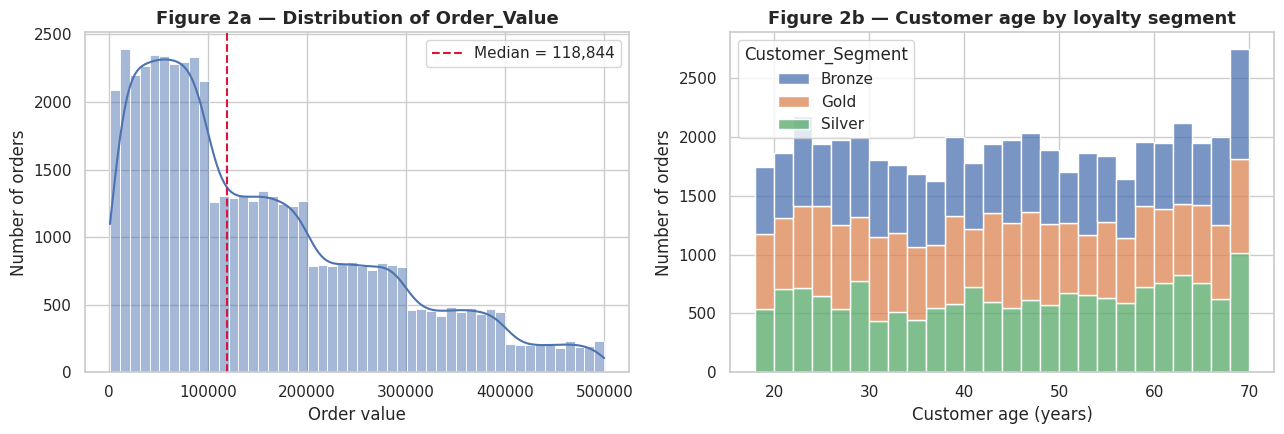

In [17]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
sns.histplot(df.Order_Value, bins=50, kde=True, ax=ax[0], color=sns.color_palette("deep")[0])
ax[0].axvline(df.Order_Value.median(), color="crimson", ls="--", label=f"Median = {df.Order_Value.median():,.0f}")
ax[0].set_title("Figure 2a — Distribution of Order_Value")
ax[0].set_xlabel("Order value"); ax[0].set_ylabel("Number of orders"); ax[0].legend()
sns.histplot(data=df, x="Customer_Age", hue="Customer_Segment", multiple="stack", bins=26, ax=ax[1])
ax[1].set_title("Figure 2b — Customer age by loyalty segment")
ax[1].set_xlabel("Customer age (years)"); ax[1].set_ylabel("Number of orders")
save_fig("02_order_value_and_age.png")

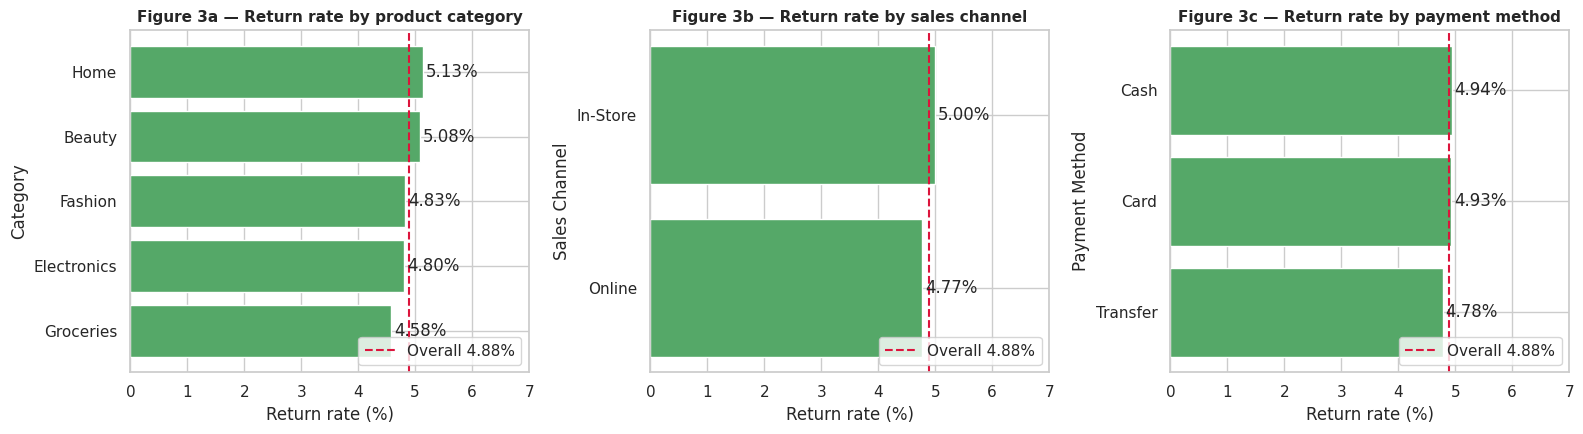

In [18]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
for a, col, title in zip(ax, ["Category", "Sales_Channel", "Payment_Method"],
                         ["Figure 3a — Return rate by product category", "Figure 3b — Return rate by sales channel",
                          "Figure 3c — Return rate by payment method"]):
    rate = df.groupby(col, observed=True).Is_Returned.mean().mul(100).sort_values()
    bars = a.barh(rate.index.astype(str), rate.values, color=sns.color_palette("deep")[2])
    a.bar_label(bars, fmt="%.2f%%", padding=2)
    a.axvline(df.Is_Returned.mean() * 100, color="crimson", ls="--", label="Overall 4.88%")
    a.set_title(title, fontsize=11); a.set_xlabel("Return rate (%)"); a.set_ylabel(col.replace("_", " ")); a.set_xlim(0, 7); a.legend(loc="lower right")
save_fig("03_return_rate_by_group.png")

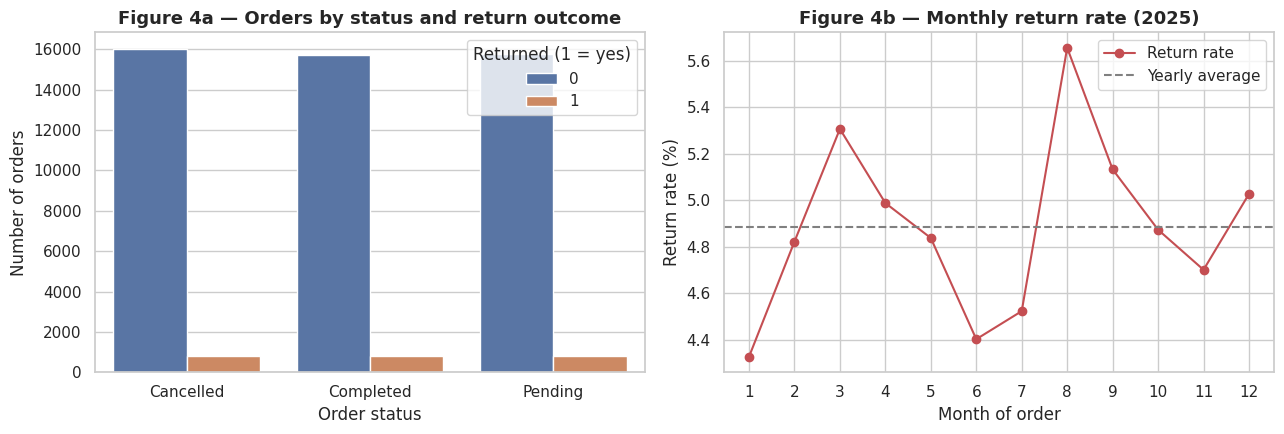

In [19]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
sns.countplot(data=df, x="Order_Status", hue="Is_Returned", ax=ax[0])
ax[0].set_title("Figure 4a — Orders by status and return outcome")
ax[0].set_xlabel("Order status"); ax[0].set_ylabel("Number of orders"); ax[0].legend(title="Returned (1 = yes)")
monthly = df.groupby("Order_Month").agg(orders=("Order_ID", "count"), return_rate=("Is_Returned", "mean"))
ax[1].plot(monthly.index, monthly.return_rate * 100, marker="o", color=sns.color_palette("deep")[3], label="Return rate")
ax[1].axhline(df.Is_Returned.mean() * 100, color="grey", ls="--", label="Yearly average")
ax[1].set_title("Figure 4b — Monthly return rate (2025)")
ax[1].set_xlabel("Month of order"); ax[1].set_ylabel("Return rate (%)"); ax[1].set_xticks(range(1, 13)); ax[1].legend()
save_fig("04_status_and_monthly_returns.png")

**Observations.** Return rates are close to the 4.88% average in every category, channel, payment method and month, so there is no obvious segment that returns more. Order status is split almost evenly into thirds (Completed / Pending / Cancelled), which matters for the business: a Cancelled order should not count as revenue, even though it has an `Order_Value`.

## 5. Part 4 — Feature Encoding & Scaling

### 5.1 Train/test split *before* anything is fitted
Scalers and encoders learn statistics (means, medians, ranges). If they learn them from the whole dataset, information from the test rows leaks into training. So we split first (80/20, stratified on `Is_Returned` to keep the 4.88% rate in both parts) and fit all scalers on the **training rows only**. The split is stored in a `Split` column so Week 3 can reuse exactly the same partition.

In [20]:
train_idx, test_idx = train_test_split(df.index, test_size=0.20, stratify=df.Is_Returned, random_state=RANDOM_STATE)
df["Split"] = "train"; df.loc[test_idx, "Split"] = "test"
print(df.groupby("Split").Is_Returned.agg(rows="size", return_rate="mean").round(4))

        rows  return_rate
Split                    
test   10000       0.0488
train  40000       0.0488


### 5.2 Encoding
| Technique | Applied to | Why |
|---|---|---|
| **Ordinal encoding** | `Customer_Segment` (Bronze < Silver < Gold), `Age_Band` (youngest → oldest) | These categories have a natural order, so numbers 0, 1, 2… keep that information. |
| **Label encoding** | `Sales_Channel`, `Gender` (two levels each) | With only two levels a single 0/1 column is enough; no false ordering can arise. |
| **One-hot encoding** | `Payment_Method`, `Order_Status`, `Category`, `Customer_State`, `Store_Region` | Nominal categories with no order. One-hot avoids implying that, say, "Transfer" is greater than "Card". The first level of each is dropped to avoid perfect collinearity in linear models. |

`Brand`/`Product_Name` were not encoded because their ~500 unique values would add hundreds of sparse columns for no gain.

In [21]:
X = df.copy()

# Ordinal encoding (explicit order)
ord_enc = OrdinalEncoder(categories=[["Bronze", "Silver", "Gold"], ["18-29", "30-44", "45-59", "60+"]])
X[["Customer_Segment_Ord", "Age_Band_Ord"]] = ord_enc.fit_transform(X[["Customer_Segment", "Age_Band"]].astype(str))

# Label encoding for binary variables
label_maps = {}
for col in ["Sales_Channel", "Gender"]:
    le = LabelEncoder().fit(X[col].astype(str))
    X[col + "_Enc"] = le.transform(X[col].astype(str))
    label_maps[col] = {cls: int(i) for i, cls in enumerate(le.classes_)}
print("Label-encoding maps:", label_maps)

# One-hot encoding for nominal variables
onehot_cols = ["Payment_Method", "Order_Status", "Category", "Customer_State", "Store_Region"]
X = pd.get_dummies(X, columns=onehot_cols, drop_first=True, dtype=int)

X = X.drop(columns=["Customer_Segment", "Age_Band", "Sales_Channel", "Gender", "Net_Value_If_Pct_Discount"])
print("Encoded table:", X.shape)
print("Any non-numeric column left (besides Order_ID/Split)?",
      [c_ for c_ in X.columns if c_ not in ("Order_ID", "Split") and not pd.api.types.is_numeric_dtype(X[c_])])

Label-encoding maps: {'Sales_Channel': {'In-Store': 0, 'Online': 1}, 'Gender': {'Female': 0, 'Male': 1}}
Encoded table: (50000, 48)
Any non-numeric column left (besides Order_ID/Split)? []


### 5.3 Scaling
Instead of forcing one scaler on everything, the choice follows a simple, checkable rule based on each column's shape *in the training data*:

| Scaler | Rule | Why |
|---|---|---|
| **RobustScaler** (median & IQR) | skewed columns, \|skew\| > 0.5 | Median/IQR are not pulled by the long tail or by outliers. |
| **MinMaxScaler** (0 → 1) | bounded columns with few distinct integer values (Quantity, Discount, month, ordinal codes…) | Keeps their natural bounded range and interpretability. |
| **StandardScaler** (mean 0, SD 1) | remaining roughly symmetric continuous columns | Standard choice for distance-based and linear models. |

Binary and one-hot columns are already 0/1 and are left unscaled. **Targets are never scaled** (`Order_Value`, `Is_Returned` stay in their original units).

In [22]:
target_cols = ["Is_Returned", "Order_Value"]
no_scale = {"Order_ID", "Split", *target_cols}
binary_like = [c_ for c_ in X.columns if c_ not in no_scale and X[c_].nunique() == 2]
to_scale = [c_ for c_ in X.columns if c_ not in no_scale and c_ not in binary_like]

train = X[X.Split == "train"]
rows = []
for col in to_scale:
    skew, nun = train[col].skew(), train[col].nunique()
    if nun <= 12:            scaler = "MinMaxScaler"
    elif abs(skew) > 0.5:    scaler = "RobustScaler"
    else:                    scaler = "StandardScaler"
    rows.append({"feature": col, "skew": round(skew, 2), "distinct_values": nun, "scaler": scaler})
scale_plan = pd.DataFrame(rows).sort_values(["scaler", "feature"]).reset_index(drop=True)
results["scale_plan"] = scale_plan.to_dict("records")
scale_plan

,feature,skew,distinct_values,scaler
0,Age_Band_Ord,0.02,4,MinMaxScaler
1,Customer_Segment_Ord,-0.03,3,MinMaxScaler
2,Discount_Pct,0.01,5,MinMaxScaler
3,Order_DayOfWeek,0.01,7,MinMaxScaler
4,Order_Month,-0.01,12,MinMaxScaler
5,Order_Quarter,-0.02,4,MinMaxScaler
6,Quantity,0.00,5,MinMaxScaler
7,Gross_Value,0.89,36684,RobustScaler
8,Prior_Orders,0.64,24,RobustScaler
9,Shipping_Share,9.95,39997,RobustScaler


In [23]:
scalers, X_scaled = {}, X.copy()
for name, cls in [("MinMaxScaler", MinMaxScaler), ("RobustScaler", RobustScaler), ("StandardScaler", StandardScaler)]:
    cols = scale_plan.loc[scale_plan.scaler == name, "feature"].tolist()
    if not cols:
        continue
    sc = cls().fit(train[cols])                      # fit on TRAIN only
    X_scaled[cols] = sc.transform(X[cols])           # apply to all rows
    scalers[name] = (sc, cols)
    print(f"{name:15s} -> {len(cols)} columns: {cols}")
print("\nBinary / one-hot columns left as they are:", len(binary_like))

MinMaxScaler    -> 7 columns: ['Age_Band_Ord', 'Customer_Segment_Ord', 'Discount_Pct', 'Order_DayOfWeek', 'Order_Month', 'Order_Quarter', 'Quantity']
RobustScaler    -> 3 columns: ['Gross_Value', 'Prior_Orders', 'Shipping_Share']
StandardScaler  -> 9 columns: ['Cost_Price', 'Customer_Age', 'Customer_Tenure_Days', 'Price_vs_Catalog_Gap', 'Selling_Price', 'Shipping_Cost', 'Store_Age_Years', 'Unit_Margin_Pct', 'Unit_Price']

Binary / one-hot columns left as they are: 25


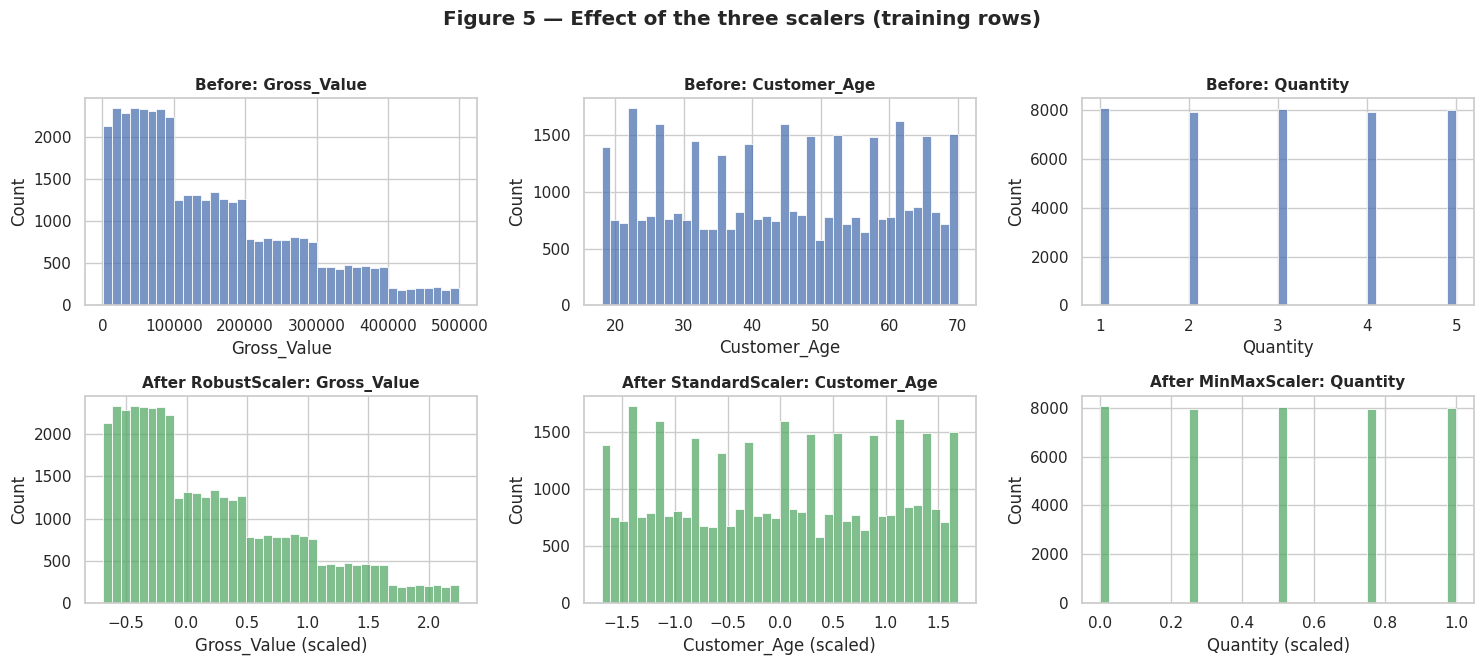

In [24]:
# Before/after visual: one example of each scaler
examples = [("Gross_Value", "RobustScaler"), ("Customer_Age", "StandardScaler"), ("Quantity", "MinMaxScaler")]
fig, ax = plt.subplots(2, 3, figsize=(15, 6.5))
for j, (col, name) in enumerate(examples):
    sns.histplot(X.loc[X.Split == "train", col], bins=40, ax=ax[0, j], color=sns.color_palette("deep")[0])
    ax[0, j].set_title(f"Before: {col}", fontsize=11); ax[0, j].set_xlabel(col); ax[0, j].set_ylabel("Count")
    sns.histplot(X_scaled.loc[X_scaled.Split == "train", col], bins=40, ax=ax[1, j], color=sns.color_palette("deep")[2])
    ax[1, j].set_title(f"After {name}: {col}", fontsize=11); ax[1, j].set_xlabel(f"{col} (scaled)"); ax[1, j].set_ylabel("Count")
fig.suptitle("Figure 5 — Effect of the three scalers (training rows)", fontweight="bold", y=1.02)
save_fig("05_scaling_before_after.png")

**Reading Figure 5.** Scaling changes the *units*, not the *shape*: the distributions look identical, but they now sit on comparable ranges (RobustScaler centres on the median; StandardScaler on the mean; MinMaxScaler squeezes into 0–1). This stops large-number columns such as `Gross_Value` (up to about 500,000) from dominating small ones such as `Quantity` (1–5) in distance-based and gradient-based models.

## 6. Part 5 — Outlier Detection & Feature Selection

### 6.1 Outlier detection (IQR, Z-score, box plots)
Outliers are measured on the **original, unscaled** values so the numbers are interpretable.

In [25]:
out_cols = ["Gross_Value", "Order_Value", "Shipping_Cost", "Unit_Price", "Customer_Age",
            "Customer_Tenure_Days", "Prior_Orders", "Store_Age_Years", "Shipping_Share"]
rows = []
for col in out_cols:
    v = df[col]
    q1, q3 = v.quantile([0.25, 0.75]); iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    z = (v - v.mean()) / v.std()
    rows.append({"feature": col, "min": round(v.min(), 2), "max": round(v.max(), 2), "skew": round(v.skew(), 2),
                 "IQR_lower_fence": round(lo, 2), "IQR_upper_fence": round(hi, 2),
                 "IQR_outliers": int(((v < lo) | (v > hi)).sum()), "Z>3_outliers": int((z.abs() > 3).sum())})
outlier_table = pd.DataFrame(rows)
outlier_table["IQR_pct"] = (outlier_table.IQR_outliers / len(df) * 100).round(2)
results["outliers"] = outlier_table.to_dict("records")
outlier_table

,feature,min,max,skew,IQR_lower_fence,IQR_upper_fence,IQR_outliers,Z>3_outliers,IQR_pct
0,Gross_Value,1003.00,499975.00,0.89,-198794.25,480549.75,410,0,0.82
1,Order_Value,993.00,499960.00,0.89,-198788.50,480533.50,410,0,0.82
2,Shipping_Cost,500.00,5000.00,0.00,-1729.00,7223.00,0,0,0.00
3,Unit_Price,1003.00,99998.00,-0.01,-48562.62,149334.38,0,0,0.00
4,Customer_Age,18.00,70.00,-0.01,-12.00,100.00,0,0,0.00
5,Customer_Tenure_Days,0.00,1089.00,0.19,-595.50,1408.50,0,0,0.00
6,Prior_Orders,0.00,23.00,0.64,-5.50,14.50,557,170,1.11
7,Store_Age_Years,2.95,5.92,0.00,2.40,6.47,0,0,0.00
8,Shipping_Share,0.00,4.54,9.79,-0.05,0.11,5428,800,10.86


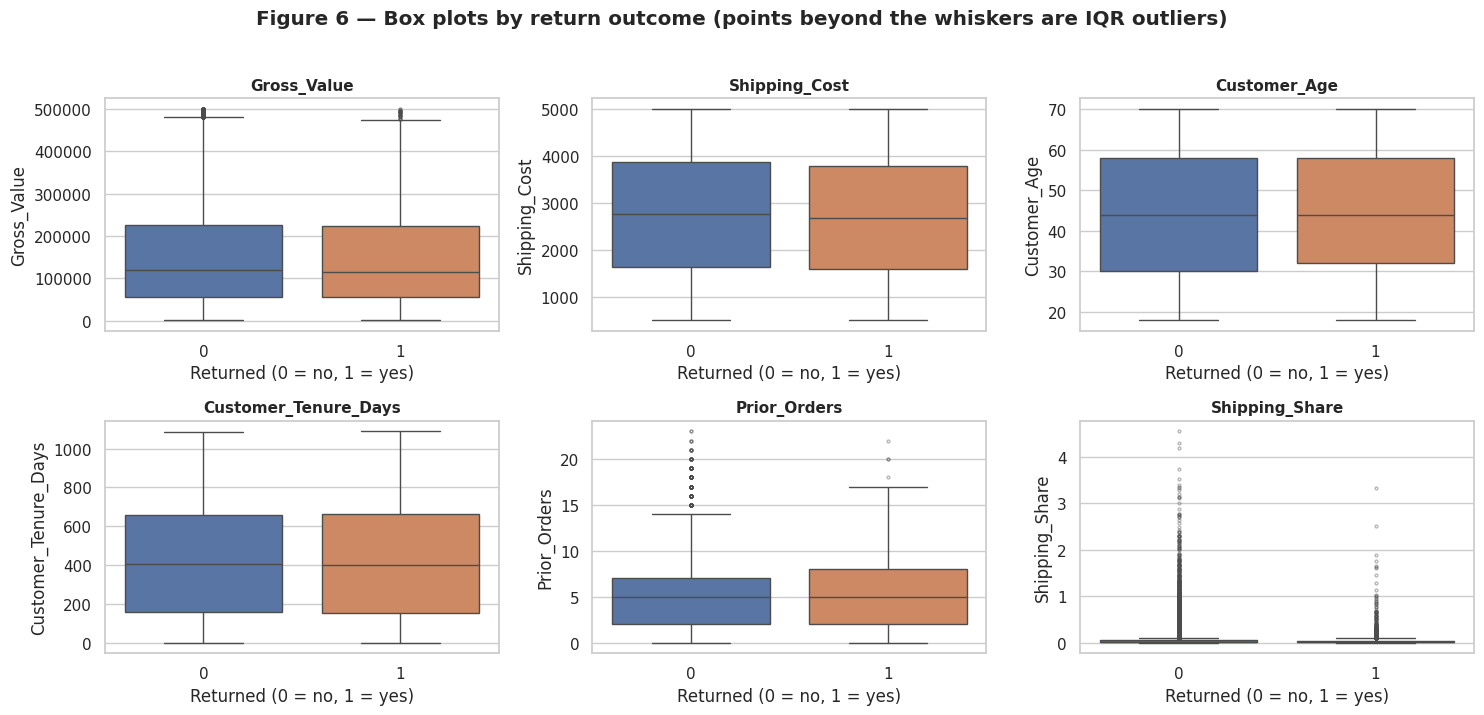

In [26]:
fig, ax = plt.subplots(2, 3, figsize=(15, 7))
for a, col in zip(ax.ravel(), ["Gross_Value", "Shipping_Cost", "Customer_Age", "Customer_Tenure_Days", "Prior_Orders", "Shipping_Share"]):
    sns.boxplot(data=df, x="Is_Returned", y=col, ax=a, palette="deep", showfliers=True, flierprops={"markersize": 2, "alpha": .4})
    a.set_title(f"{col}", fontsize=11); a.set_xlabel("Returned (0 = no, 1 = yes)"); a.set_ylabel(col)
fig.suptitle("Figure 6 — Box plots by return outcome (points beyond the whiskers are IQR outliers)", fontweight="bold", y=1.02)
save_fig("06_boxplots_outliers.png")

**Outlier decision (Business Question 5).**
* `Gross_Value`: the IQR rule flags about 0.8% of orders (roughly 410), but **no** value is beyond 3 standard deviations. The flagged baskets are simply the top of a right-skewed but legitimate range (price up to about 100,000 × quantity up to 5 = about 500,000, which is the maximum). They are real, high-value customers, not errors.
* `Shipping_Share` has extreme tails (about 11% flagged by IQR, skew 9.8): it divides shipping by basket value, so tiny baskets create very large ratios. It is a derived artefact, not bad raw data, and it is removed later by the variance threshold.
* `Prior_Orders` flags about 1.1% of rows (customers with 15 or more earlier orders, maximum 23). These are loyal repeat buyers, so the values are genuine.
* Age, shipping cost, unit price, tenure and store age show no outliers.

**Treatment: keep all rows.** Deleting or capping the high baskets would erase exactly the customers a retailer cares most about, and would bias `Order_Value` predictions downward. Instead, outlier influence is controlled through **RobustScaler** on the skewed columns (median/IQR ignore the tail), and, if a model is later sensitive to the tail, a log transform of `Order_Value` can be tested in Week 3.

### 6.2 Feature selection
Four complementary methods are applied on the **training rows only**:
1. **Variance threshold**: remove columns that barely change.
2. **Correlation analysis**: remove one of each pair of near-duplicates (|r| > 0.85).
3. **Leakage check**: find features that reconstruct a target.
4. **Feature importance with a noise "probe"**: rank features for `Is_Returned` using a Random Forest and mutual information, and compare each to a column of pure random noise. A real feature must beat the noise.

In [27]:
feature_cols = [c_ for c_ in X_scaled.columns if c_ not in no_scale]
Xtr = X_scaled.loc[X_scaled.Split == "train", feature_cols]
ytr_clf = X_scaled.loc[X_scaled.Split == "train", "Is_Returned"]
ytr_reg = X_scaled.loc[X_scaled.Split == "train", "Order_Value"]
print(len(feature_cols), "candidate features")

# --- 1. Variance threshold (on a 0-1 rescaled copy so variances are comparable) ---------
mm = MinMaxScaler().fit_transform(Xtr)
vt = VarianceThreshold(threshold=0.01).fit(mm)
low_var = [f for f, keep in zip(feature_cols, vt.get_support()) if not keep]
print("Removed by variance threshold (<0.01):", low_var or "none")
variance_table = pd.Series(mm.var(axis=0), index=feature_cols).sort_values().head(8).round(4)
print("\nLowest-variance features:\n", variance_table.to_string())

44 candidate features
Removed by variance threshold (<0.01): ['Shipping_Share']

Lowest-variance features:
 Shipping_Share          0.0012
Prior_Orders            0.0255
Price_vs_Catalog_Gap    0.0384
Store_Age_Years         0.0491
Gross_Value             0.0569
Selling_Price           0.0664
Customer_Tenure_Days    0.0728
Unit_Margin_Pct         0.0782


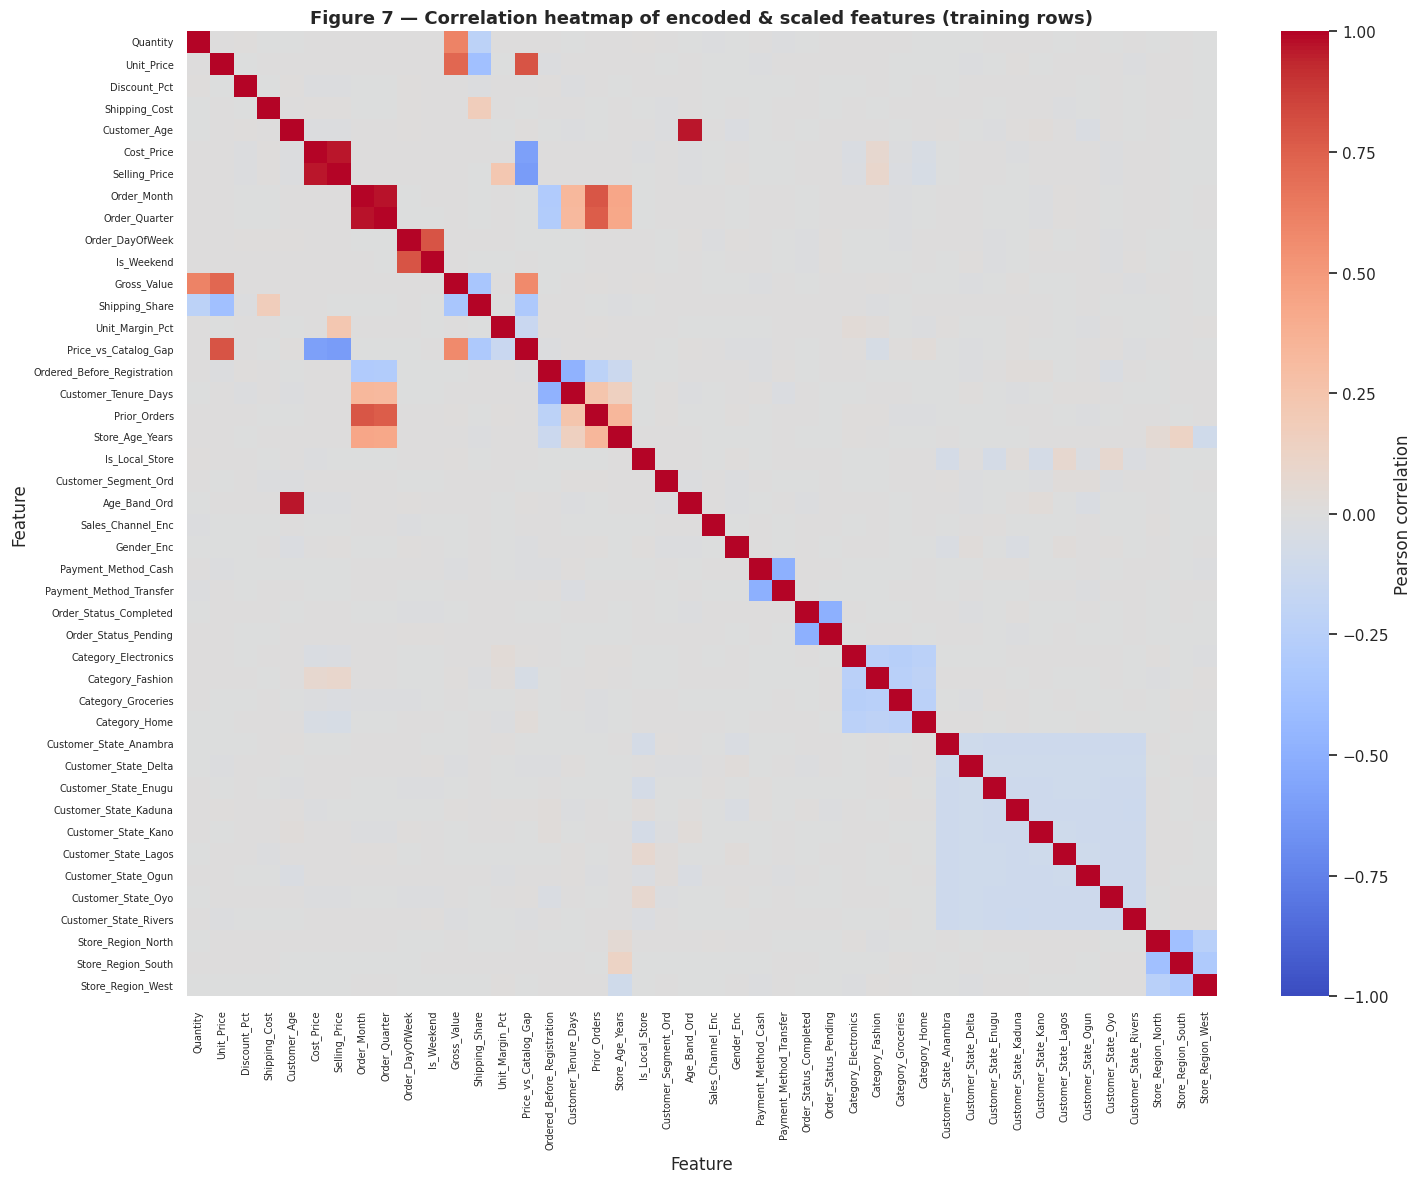

,feature_a,feature_b,r
316,Order_Month,Order_Quarter,0.971540
197,Customer_Age,Age_Band_Ord,0.966665
226,Cost_Price,Selling_Price,0.964723


In [28]:
# --- 2. Correlation analysis ------------------------------------------------------------
corr = Xtr.corr()
fig, ax = plt.subplots(figsize=(15, 12))
sns.heatmap(corr, cmap="coolwarm", center=0, vmin=-1, vmax=1, ax=ax, cbar_kws={"label": "Pearson correlation"},
            xticklabels=True, yticklabels=True, linewidths=0)
ax.set_title("Figure 7 — Correlation heatmap of encoded & scaled features (training rows)")
ax.set_xlabel("Feature"); ax.set_ylabel("Feature")
plt.xticks(fontsize=7, rotation=90); plt.yticks(fontsize=7)
save_fig("07_correlation_heatmap.png")

# list pairs above 0.85
pairs = (corr.where(np.triu(np.ones(corr.shape), 1).astype(bool)).stack()
             .rename("r").reset_index().rename(columns={"level_0": "feature_a", "level_1": "feature_b"}))
high = pairs[pairs.r.abs() > 0.85].sort_values("r", key=abs, ascending=False)
high

In [29]:
# Greedy removal: from each highly-correlated pair drop the feature that is more correlated with all the others
to_drop_corr = []
remaining = [f for f in feature_cols if f not in low_var]
for _, row in high.iterrows():
    a, b = row.feature_a, row.feature_b
    if a in to_drop_corr or b in to_drop_corr:
        continue
    drop = a if corr[a].abs().mean() > corr[b].abs().mean() else b
    to_drop_corr.append(drop)
    print(f"|r| = {abs(row.r):.3f}  ({a}, {b})  ->  drop '{drop}'")
selected = [f for f in remaining if f not in to_drop_corr]
print(f"\nKept {len(selected)} of {len(feature_cols)} features after variance + correlation filtering")

|r| = 0.972  (Order_Month, Order_Quarter)  ->  drop 'Order_Month'
|r| = 0.967  (Customer_Age, Age_Band_Ord)  ->  drop 'Customer_Age'
|r| = 0.965  (Cost_Price, Selling_Price)  ->  drop 'Selling_Price'

Kept 40 of 44 features after variance + correlation filtering


Correlation with the regression target Order_Value:
 Gross_Value     1.0000
Quantity        0.6019
Unit_Price      0.7240
Discount_Pct    0.0056


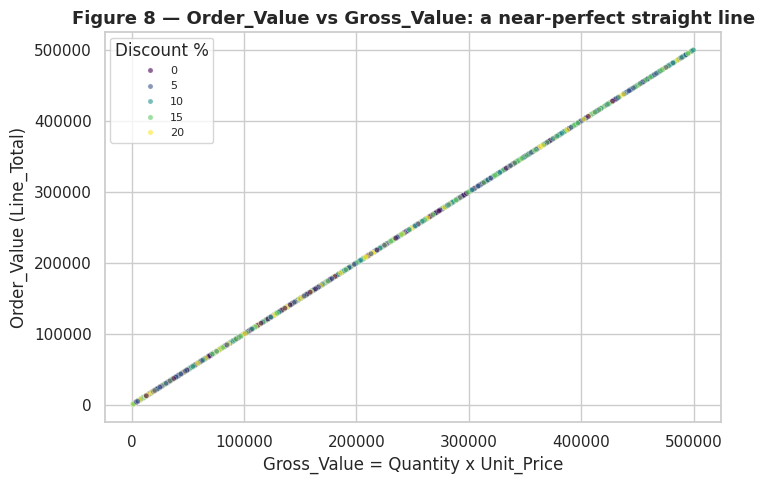

In [30]:
# --- 3. Leakage check -------------------------------------------------------------------
leak = pd.concat([X_scaled.loc[X_scaled.Split == "train", ["Order_Value"]],
                  Xtr[["Gross_Value", "Quantity", "Unit_Price", "Discount_Pct"]]], axis=1).corr()["Order_Value"].drop("Order_Value")
print("Correlation with the regression target Order_Value:\n", leak.round(4).to_string())

fig, ax = plt.subplots(figsize=(7.5, 5))
samp = df.sample(5000, random_state=RANDOM_STATE)
sns.scatterplot(data=samp, x="Gross_Value", y="Order_Value", hue="Discount_Pct", palette="viridis", s=14, alpha=.6, ax=ax)
ax.set_title("Figure 8 — Order_Value vs Gross_Value: a near-perfect straight line")
ax.set_xlabel("Gross_Value = Quantity x Unit_Price"); ax.set_ylabel("Order_Value (Line_Total)"); ax.legend(title="Discount %", fontsize=8)
save_fig("08_leakage_scatter.png")
results["corr_gross_order"] = float(df[["Gross_Value", "Order_Value"]].corr().iloc[0, 1])

**Leakage finding.** `Gross_Value` correlates with `Order_Value` at about 1.000, and Figure 8 shows the points lying on a straight line (the discount only shifts them down by a negligible amount). A regression that is given `Gross_Value` — or all three of `Quantity`, `Unit_Price`, `Discount_Pct` — is not *predicting* anything; it is doing arithmetic. That is the same trap as Week 1's R² = 1.0.

**Rule adopted:** two feature sets are produced. The classification set keeps `Gross_Value`; the regression set **excludes it**. The notebook also reports regression performance both with and without the arithmetic inputs, so the difference is visible.

In [31]:
# --- 4. Feature importance for Is_Returned, with a random-noise probe ---------------------
rng = np.random.default_rng(RANDOM_STATE)
Xp = Xtr[selected].copy()
Xp["RANDOM_PROBE"] = rng.normal(size=len(Xp))

rf = RandomForestClassifier(n_estimators=300, max_depth=8, min_samples_leaf=50, class_weight="balanced",
                            n_jobs=-1, random_state=RANDOM_STATE).fit(Xp, ytr_clf)
imp = pd.Series(rf.feature_importances_, index=Xp.columns, name="rf_importance")
mi = pd.Series(mutual_info_classif(Xp, ytr_clf, random_state=RANDOM_STATE), index=Xp.columns, name="mutual_info")
rank = pd.concat([imp, mi], axis=1).sort_values("rf_importance", ascending=False)
probe_imp = rank.loc["RANDOM_PROBE", "rf_importance"]
rank["beats_noise"] = rank.rf_importance > probe_imp
results["n_beat_noise"] = int(rank.drop("RANDOM_PROBE").beats_noise.sum())
rank.head(12).round(4)

,rf_importance,mutual_info,beats_noise
Price_vs_Catalog_Gap,0.0856,0.0015,True
Shipping_Cost,0.0842,0.0000,True
Store_Age_Years,0.0764,0.0008,True
Unit_Price,0.0752,0.0000,True
Gross_Value,0.0751,0.0007,True
RANDOM_PROBE,0.0734,0.0000,False
Customer_Tenure_Days,0.0723,0.0000,False
Unit_Margin_Pct,0.0717,0.0000,False
Cost_Price,0.0698,0.0000,False
Prior_Orders,0.0355,0.0002,False


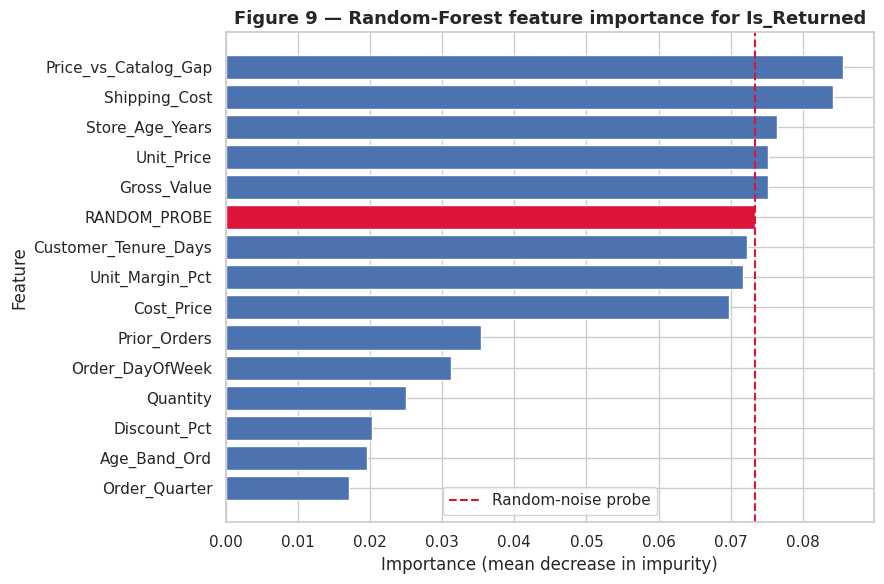

5-fold ROC-AUC on the selected features: 0.496 +/- 0.012  (0.50 = random guessing)


In [32]:
top = rank.head(15).iloc[::-1]
colors = ["crimson" if i == "RANDOM_PROBE" else sns.color_palette("deep")[0] for i in top.index]
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(top.index, top.rf_importance, color=colors)
ax.axvline(probe_imp, color="crimson", ls="--", label="Random-noise probe")
ax.set_title("Figure 9 — Random-Forest feature importance for Is_Returned")
ax.set_xlabel("Importance (mean decrease in impurity)"); ax.set_ylabel("Feature"); ax.legend()
save_fig("09_feature_importance.png")

cv = StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE)
rf_cv = RandomForestClassifier(n_estimators=150, max_depth=8, min_samples_leaf=50, class_weight="balanced",
                               n_jobs=-1, random_state=RANDOM_STATE)
auc = cross_val_score(rf_cv, Xtr[selected], ytr_clf, cv=cv, scoring="roc_auc")
results["clf_auc_cv"] = [round(float(auc.mean()), 4), round(float(auc.std()), 4)]
print(f"5-fold ROC-AUC on the selected features: {auc.mean():.3f} +/- {auc.std():.3f}  (0.50 = random guessing)")

**Importance result (Business Question 6).** The cross-validated ROC-AUC is about 0.50 (0.4955 ± 0.0116), which is no better than guessing. Only 5 of the 39 features score above the random-noise probe, and only by a hair (the best is 0.086 against a probe of 0.073), while mutual information is essentially zero for every feature. Return rates also barely move across any group (between about 4.1% and 5.7%). In plain words: **with the information in these tables, whether an order is returned cannot be predicted.** That is a legitimate result of preprocessing, not a bug in it, and it explains the Week 1 outcome (accuracy looked high only because 95% of orders are not returned).

So the classification feature set is chosen on *redundancy and sense* (variance + correlation + no leakage), **not** by keeping only the five "winners", because their lead over noise is not meaningful. The report states honestly that predictive power is limited. Better returns prediction would need richer data (e.g. product-level return history, delivery delays, customer reviews).

In [33]:
# --- Regression: what do the arithmetic inputs do? --------------------------------------
reg_features = [f for f in selected if f != "Gross_Value"]
no_arith = [f for f in reg_features if f not in ("Quantity", "Unit_Price", "Discount_Pct", "Price_vs_Catalog_Gap", "Shipping_Share")]
te = X_scaled[X_scaled.Split == "test"]
def reg_r2(cols):
    m = RandomForestRegressor(n_estimators=80, max_depth=12, min_samples_leaf=20, n_jobs=-1, random_state=RANDOM_STATE)
    m.fit(Xtr[cols], ytr_reg)
    return round(r2_score(te.Order_Value, m.predict(te[cols])), 3)
r2_all   = reg_r2(selected)
r2_noleak = reg_r2(reg_features)
r2_none  = reg_r2(no_arith)
print(f"R2 with Gross_Value (leaky)                      : {r2_all}")
print(f"R2 without Gross_Value (Quantity, Price, Discount kept): {r2_noleak}")
print(f"R2 without any arithmetic inputs                 : {r2_none}")
results["r2"] = {"with_gross_value": r2_all, "without_gross_value": r2_noleak, "without_arithmetic_inputs": r2_none}

R2 with Gross_Value (leaky)                      : 1.0
R2 without Gross_Value (Quantity, Price, Discount kept): 1.0
R2 without any arithmetic inputs                 : -0.002


**Regression result.** With `Gross_Value` the test R² is 1.00, and **without** `Gross_Value` it is still 1.00, because `Quantity` and `Unit_Price` together *are* the formula. Only when those and the columns derived from them (`Discount_Pct`, `Price_vs_Catalog_Gap`, `Shipping_Share`) are removed does R² collapse to about zero (−0.002): customer, store and time information explain essentially none of the order value. **Recommendation for Week 3:** state clearly which inputs are available *at prediction time*. If the goal is to forecast order value *before* quantity and price are known, no feature in this dataset can do it; otherwise report the high R² as arithmetic, not as model skill.

## 7. Part 6 — Machine-Learning-Ready Dataset
Two files are saved:

| File | Contents | Use |
|---|---|---|
| `ShopSmart_Cleaned.csv` | Clean, human-readable table before encoding/scaling (no personal data) | Reporting, Power BI/SQL, further EDA |
| `ShopSmart_ML_Ready.csv` | Encoded + scaled selected features, both targets, `Split` column | Model training in Week 3 |

Fitted scalers/encoders and the feature lists are also saved so the same transformations can be re-applied to new data.

In [34]:
final_cols = ["Order_ID", "Split", "Is_Returned", "Order_Value"] + selected
ml_ready = X_scaled[final_cols].copy()

# --- readiness checks ---
assert ml_ready.isna().sum().sum() == 0, "missing values remain"
assert all(pd.api.types.is_numeric_dtype(ml_ready[c_]) for c_ in final_cols if c_ not in ("Order_ID", "Split"))
assert not np.isinf(ml_ready[selected].to_numpy()).any(), "infinite values remain"
assert ml_ready.Order_ID.is_unique and len(ml_ready) == len(df)
assert set(ml_ready.Split.unique()) == {"train", "test"}

ml_ready.to_csv(OUT / "ShopSmart_ML_Ready.csv", index=False)
cleaned.to_csv(OUT / "ShopSmart_Cleaned.csv", index=False)

feature_sets = {
    "classification_Is_Returned": selected,
    "regression_Order_Value_no_Gross_Value": reg_features,
    "regression_Order_Value_no_arithmetic_inputs": no_arith,
    "removed_low_variance": low_var, "removed_high_correlation": to_drop_corr,
    "target_columns": ["Is_Returned", "Order_Value"], "row_key": "Order_ID", "split_column": "Split",
    "label_encoding": label_maps, "random_state": RANDOM_STATE,
}
json.dump(feature_sets, open(MOD / "feature_sets.json", "w"), indent=2)
joblib.dump({"ordinal_encoder": ord_enc, "scalers": scalers, "scale_plan": scale_plan, "onehot_columns": onehot_cols},
            MOD / "preprocessing_artifacts.joblib")

print("ML-ready file :", ml_ready.shape, "->", OUT / "ShopSmart_ML_Ready.csv")
print("Cleaned file  :", cleaned.shape, "->", OUT / "ShopSmart_Cleaned.csv")
print("\nReadiness checks passed: no missing, no infinite, all numeric, unique keys, train/test present.")
ml_ready.head()

ML-ready file : (50000, 44) -> ../data/processed/ShopSmart_ML_Ready.csv
Cleaned file  : (50000, 33) -> ../data/processed/ShopSmart_Cleaned.csv

Readiness checks passed: no missing, no infinite, all numeric, unique keys, train/test present.


,Order_ID,Split,Is_Returned,Order_Value,Quantity,Unit_Price,Discount_Pct,Shipping_Cost,Cost_Price,Order_Quarter,...,Customer_State_Enugu,Customer_State_Kaduna,Customer_State_Kano,Customer_State_Lagos,Customer_State_Ogun,Customer_State_Oyo,Customer_State_Rivers,Store_Region_North,Store_Region_South,Store_Region_West
0,ORD000001,train,0,77979,0.00,0.964156,0.50,0.834030,1.600941,0.666667,...,0,0,0,1,0,0,0,0,1,0
1,ORD000002,train,0,33715,0.50,-1.368283,0.25,0.092727,-1.489007,0.000000,...,0,1,0,0,0,0,0,1,0,0
2,ORD000003,test,0,47170,0.25,-0.936557,1.00,-1.411477,0.401800,1.000000,...,0,0,0,0,0,0,0,0,1,0
3,ORD000004,train,0,279683,0.75,0.682267,0.25,-1.419963,0.278303,0.666667,...,0,0,0,0,0,1,0,0,1,0
4,ORD000005,train,0,266720,1.00,0.102975,0.00,-0.780483,0.687689,0.000000,...,0,0,0,0,0,0,0,0,0,1


In [35]:
print("Train/test class balance:")
print(ml_ready.groupby("Split").Is_Returned.agg(rows="size", returned="sum", rate="mean").round(4))
print("\nFeature count by type:")
print({"total_selected": len(selected),
       "binary_or_onehot": len([f for f in selected if f in binary_like]),
       "scaled_numeric": len([f for f in selected if f in to_scale])})
results.update({"n_features_candidate": len(feature_cols), "n_features_selected": len(selected),
                "removed_low_variance": low_var, "removed_high_correlation": to_drop_corr,
                "selected": selected, "reg_features": reg_features, "no_arith": no_arith,
                "train_rows": int((ml_ready.Split == "train").sum()), "test_rows": int((ml_ready.Split == "test").sum()),
                "top_importance": rank.head(6).round(4).reset_index().rename(columns={"index": "feature"}).to_dict("records"),
                "cleaned_shape": list(cleaned.shape), "ml_shape": list(ml_ready.shape)})
json.dump(results, open(REP / "results.json", "w"), indent=2, default=str)

Train/test class balance:
        rows  returned    rate
Split                         
test   10000       488  0.0488
train  40000      1954  0.0488

Feature count by type:
{'total_selected': 40, 'binary_or_onehot': 25, 'scaled_numeric': 15}


### 7.1 Summary of all preprocessing steps

| # | Step | What was done | Outcome |
|---|---|---|---|
| 1 | Inspection | Loaded 9 tables; checked shape, types, missing, duplicates, statistics | No missing cells, no exact duplicates |
| 2 | Logic audit | 13 business-rule checks | Leakage in `Line_Total`, inconsistent returns data, impossible tenure, conflicting prices |
| 3 | Cleaning | Stripped/standardised text, parsed dates, validated ranges, collapsed returns to one flag per order | One validated 50,000-row order table |
| 4 | Feature engineering | 14 new features (time, value, customer, store) | Seasonality, basket size, margin, history |
| 5 | Column removal | Dropped names, e-mail, phone, IDs, constant and high-cardinality columns | Personal data removed; model-relevant columns kept |
| 6 | Split | 80/20 stratified on `Is_Returned` (seed 42) | Return rate 4.88% in both parts |
| 7 | Encoding | Ordinal (2), label (2), one-hot (5 columns, first level dropped) | All features numeric |
| 8 | Scaling | Robust / MinMax / Standard chosen by a skew-and-range rule, fitted on train only | No test-set leakage |
| 9 | Outliers | IQR + Z-score + box plots | Kept all rows (legitimate high baskets); Robust scaling limits influence |
| 10 | Feature selection | Variance threshold, correlation pruning, leakage check, importance vs noise probe | Redundant and leaky features removed |
| 11 | Output | `ShopSmart_ML_Ready.csv`, `ShopSmart_Cleaned.csv`, feature lists, fitted transformers | Checked: no missing/infinite values, numeric, unique keys |

### 7.2 Answers to the seven business questions

**1. What data-quality issues exist?** No missing values and no exact duplicates, but 13 logic problems. The biggest: `Line_Total` subtracts the 0–20 `Discount` as a flat number (100% of rows), so the regression target is arithmetic; order prices conflict with catalogue prices (100%); 67% of returns are on Cancelled/Pending orders; 50% of returns are dated before the order; 10% of orders pre-date customer registration; 11% of refunds exceed the order value; 6 of 10 states appear under several store regions; `Sub_Category` is constant.

**2. Which features require preprocessing?** Four date columns stored as text; eight categorical columns (payment method, channel, status, category, gender, segment, state, region); skewed or large-scale numerics (`Gross_Value`, `Order_Value`, prices); the returns table (collapsed to one flag per order); and personal-data columns (name, e-mail, phone) that must be removed.

**3. Which encoding techniques fit?** Ordinal for `Customer_Segment` and `Age_Band` (real order); label encoding for the two binary columns (`Sales_Channel`, `Gender`); one-hot (first level dropped) for the five nominal columns. `Brand`/`Product_Name` were not encoded because their ~500 unique values act like IDs.

**4. Which scaling method?** A mix chosen by rule and fitted on training rows only: RobustScaler for skewed columns (`Gross_Value`, `Prior_Orders`, `Shipping_Share`), MinMaxScaler for bounded integer-like columns (quantity, discount, month/quarter/day, ordinal codes), StandardScaler for the remaining symmetric continuous columns.

**5. Are there significant outliers?** The IQR rule flags 410 high-value baskets (0.82%) and 557 `Prior_Orders` values (1.1%), but none of the `Gross_Value` points is beyond 3 standard deviations. They are genuine large baskets and loyal customers, so rows were kept and RobustScaler limits their influence. `Shipping_Share` has extreme ratios from tiny baskets and was removed by the variance threshold.

**6. Which features contribute most?** For returns, none to a meaningful degree: ROC-AUC 0.4955 ± 0.0116 (random guessing), and only 5 of 39 features edge past a random-noise probe. For order value, `Quantity` and `Unit_Price` dominate, but only because they are the formula (R² = 1.00); without the arithmetic inputs R² ≈ −0.002.

**7. Is the dataset ready for model training?** *Technically yes:* 50,000 rows × 40 features, no missing or infinite values, all numeric, leakage flagged with separate feature sets, personal data removed, and a stratified train/test split. *Substantively, with caveats:* returns cannot be predicted from these tables, and order value is predictable only through arithmetic. Week 3 should use class-imbalance-aware metrics (ROC-AUC, recall, precision-recall) rather than accuracy, and the team should confirm with the data owner whether `Discount` is meant to be a percentage.